## Progetto 3 del Modulo 3

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC


In [ ]:
wine = load_wine(as_frame=True)
df = wine.frame
Xdf = df[wine.feature_names]
ydf = df['target']

print(df.describe())
print(df.dtypes)

X = wine.data
y = wine.target

print(wine.DESCR)

          alcohol  malic_acid  ...      proline      target
count  178.000000  178.000000  ...   178.000000  178.000000
mean    13.000618    2.336348  ...   746.893258    0.938202
std      0.811827    1.117146  ...   314.907474    0.775035
min     11.030000    0.740000  ...   278.000000    0.000000
25%     12.362500    1.602500  ...   500.500000    0.000000
50%     13.050000    1.865000  ...   673.500000    1.000000
75%     13.677500    3.082500  ...   985.000000    2.000000
max     14.830000    5.800000  ...  1680.000000    2.000000

[8 rows x 14 columns]
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float

# Standardizzazione

In [18]:
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

# Riduzione Dimensionale con PCA

In [19]:
pca = PCA(n_components=2)
X_pca=pca.fit_transform(X_std)

# Applicazione k-NN

In [20]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_pca, y)
y_pred_knn = knn.predict(X_pca)

accuracy = accuracy_score(y, y_pred_knn)

# Applicazione SVM

In [23]:
svm = SVC(kernel='linear')
svm.fit(X_pca, y)
y_pred_svm = svm.predict(X_pca)

accuracy = accuracy_score(y, y_pred_svm)

## Analisi e Visualizzazione

In [26]:
x_min, x_max = X_pca[:,0].min() - 1, X_pca[:,0].max() + 1
y_min, y_max = X_pca[:,1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max,0.02), np.arange(y_min, y_max, 0.02))

z_knn = knn.predict(np.c_[xx.ravel(), yy.ravel()])
z_knn = z_knn.reshape(xx.shape)

z_svm = svm.predict(np.c_[xx.ravel(), yy.ravel()])
z_svm = z_svm.reshape(xx.shape)

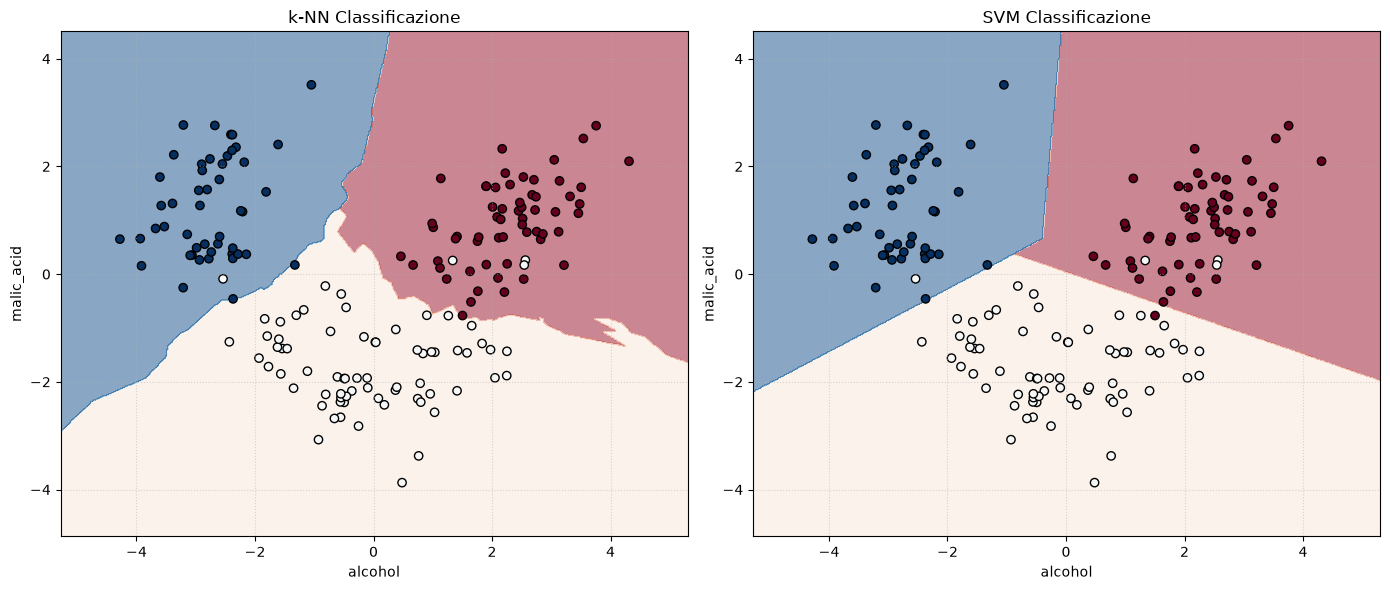

In [34]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
ax1.contourf(xx, yy, z_knn, alpha=0.5, cmap=plt.cm.RdBu)

ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', cmap=plt.cm.RdBu)

ax1.set_title(f"k-NN Classificazione")
ax1.set_xlabel(f"{wine.feature_names[0]}")
ax1.set_ylabel(f"{wine.feature_names [1]}")

ax1.set_xlim(xx.min(), xx.max())
ax1.set_ylim(yy.min(), yy.max())

ax1.grid(True, linestyle=':', alpha=0.5)


ax2.contourf(xx, yy, z_svm, alpha=0.5, cmap=plt.cm.RdBu)

ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', cmap=plt.cm.RdBu)

ax2.set_title(f"SVM Classificazione")
ax2.set_xlabel(f"{wine.feature_names[0]}")
ax2.set_ylabel(f"{wine.feature_names [1]}")

ax2.set_xlim(xx.min(), xx.max())
ax2.set_ylim(yy.min(), yy.max())

ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()